In [ ]:
# Install required packages
!pip install -q torch_geometric
!pip install -q pynndescent
!pip install -q scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.1/169.1 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.2/58.2 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.1/254.1 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 123.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.7/53.7 kB 4.6 MB/s eta 0:00:00


In [ ]:
# Import modules

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import anndata as ad
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
import torch_geometric
from torch_geometric.nn import GATConv
import pynndescent
from scipy import sparse as sp
from tqdm import tqdm

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Contrastive Model
The full contrastive model is trained to finetune both the encoded latent representation and the alignment.

# Load data

In [ ]:
# Load MERFISH AnnData
adata_st = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_spatial_train.h5ad')
adata_st

AnnData object with n_obs × n_vars = 10000 × 155
    obs: 'Cell_ID', 'Animal_ID', 'Animal_sex', 'Behavior', 'Bregma', 'Centroid_X', 'Centroid_Y', 'Cell_class', 'Neuron_cluster_ID', 'batch'
    var: 'mean', 'std'
    uns: 'Cell_class_colors', 'log1p'
    obsm: 'spatial', 'spatial3d'

In [ ]:
# Load sc data
adata_sc = sc.read_h5ad('/content/drive/My Drive/Colab Notebooks/NNDL Project/data/moffit_scRNA_train.h5ad')
adata_sc

AnnData object with n_obs × n_vars = 28390 × 155
    obs: 'Sex', 'Replicate_number', 'Cell_class', 'Non-neuronal_cluster_ID', 'Neuronal_cluster_ID'
    var: 'mean', 'std'
    uns: 'log1p'

# Dataset and DataLoader
Same as with AEs.

In [ ]:
def get_knn(location, n_neighbors):
    index = pynndescent.NNDescent(location, n_neighbors=n_neighbors)
    neighbor_idx, neighbor_dist = index.neighbor_graph
    return neighbor_idx, neighbor_dist

def knn_to_adj(knn_idx, knn_dist):

    n_samples, n_neighbors = knn_idx.shape

    row = np.repeat(np.arange(n_samples), n_neighbors)
    col = knn_idx.flatten()
    data = np.ones(n_samples * n_neighbors)

    adj_matrix = sp.csr_matrix((data, (row, col)), shape=(n_samples, n_samples))
    return adj_matrix

def location_to_edge(location, n_neighbors):
    idx, dist = get_knn(location, n_neighbors)
    adj = knn_to_adj(idx, dist)
    edge = torch_geometric.utils.from_scipy_sparse_matrix(adj)[0]
    return edge

In [ ]:
class spatialDataset(Dataset):

    def __init__(self, data_fit, location):
        data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit
        assert len(data_fit) == len(location)
        self.data_fit = data_fit
        self.location = location

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
       return self.data_fit[index], self.location[index], index

class rnaDataset(Dataset):

    def __init__(self, data_fit):
        self.data_fit = data_fit.toarray() if sp.issparse(data_fit) else data_fit

    def __len__(self):
        return len(self.data_fit)

    def __getitem__(self, index):
        return self.data_fit[index], index


class rnaCollate():
    def __init__(self, device='cpu'):
        self.device = device

    def __call__(self, batch):
        batch_fit, batch_idx = zip(*batch)  # unzip the batch
        batch_fit = torch.from_numpy(np.vstack(batch_fit)).to(self.device)  # shape: [B, D]
        batch_idx = torch.tensor(batch_idx, dtype=torch.long).to(self.device)  # shape: [B]
        return batch_fit, batch_idx


class spatialCollate():

    def __init__(self, knn = 10, device='cpu'):
        self.device = device
        self.knn = knn

    def __call__(self, batch):
        batch_fit, batch_location, batch_idx = zip(*batch)

        batch_fit = torch.from_numpy(np.vstack(batch_fit)).to(self.device)
        batch_location = np.vstack(batch_location)
        batch_edge = location_to_edge(batch_location, self.knn).to(self.device)
        batch_idx = torch.tensor(batch_idx, dtype=torch.long).to(self.device)

        return batch_fit, batch_edge, batch_idx

# Model definition

## SC Autoencoder

In [ ]:
class EncoderSC(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, dropout=0.0):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_input, d_hidden),
                                   nn.ReLU(),
                                   nn.Dropout(dropout),
                                   nn.Linear(d_hidden, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_latent))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, x):
        z = self.model(x)
        return z


class DecoderSC(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_latent, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_input))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, z):
        x = self.model(z)
        return x

## Spatial Autoencoder

In [ ]:
class GATLayer(nn.Module):
    def __init__(self, d_input, num_heads=4, n_layers=1, dropout=0.0, residual=True):
        super().__init__()
        self.residual = residual
        self.num_heads = num_heads
        self.conv_layers = nn.ModuleList()
        self.n_layers = n_layers

        for i in range(self.n_layers):
            self.conv_layers.append(GATConv(d_input, d_input, heads=num_heads, concat=False))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index):
        if self.residual:
            resid = x
        for layer in self.conv_layers:
            x = layer(x, edge_index)
            x = self.dropout(F.leaky_relu(x))
        if self.residual:
            x += resid
        return x

class EncoderST(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent, num_heads=1, n_layers=1, dropout=0.0, residual=True):
        super().__init__()

        self.pre_fc = nn.Sequential(nn.Linear(d_input, d_hidden, bias=True),
                                    nn.ReLU(),
                                    nn.Dropout(dropout),
                                    nn.Linear(d_hidden, d_latent, bias=True))
        self.post_fc = nn.Linear(d_latent, d_latent, bias=True)
        self.gat_layer = GATLayer(d_input=d_latent, num_heads=num_heads, n_layers=n_layers, dropout=dropout, residual=residual)

    def forward(self, x, e):
        z = self.pre_fc(x)
        z = self.gat_layer(z, e)
        z = self.post_fc(z)

        return z


class DecoderST(nn.Module):
    def __init__(self, d_input, d_hidden, d_latent):
        super().__init__()
        self.d_input = d_input
        self.d_latent = d_latent
        self.d_hidden = d_hidden
        self.model = nn.Sequential(nn.Linear(d_latent, d_hidden),
                                   nn.ReLU(),
                                   nn.Linear(d_hidden, d_input))
        for module in self.modules():
            if isinstance(module, nn.Linear):
                torch.nn.init.normal_(module.weight, mean=0, std=0.1)
                torch.nn.init.normal_(module.bias, mean=0, std=0.1)

    def forward(self, z):
        x = self.model(z)
        return x

## Alignment Head
This alignment head extracts the relevant section of the full alignment matrix corresponding to the current batch of spatial spots.

It allows efficient computation of the contrastive loss during training while keeping access to the full matrix for evaluation or downstream analysis.

In [ ]:
class AlignmentMatrix(nn.Module):
    def __init__(self, initial_state=None, device='cpu'):
        super().__init__()
        if initial_state is None:
            raise ValueError("initial_state for the aligment must be provided")
        else:
            initial_state = initial_state["AlignmentMatrix.M"]
            self.M = nn.Parameter(initial_state) # init to optimal alignment from previous task
        # self.M.to(device)  # already moves

    # These two methods act as forward

    def get_M_full(self):
        M_probs = F.softmax(self.M, dim=1)  # apply softmax
        return M_probs  # Full matrix

    def get_M_batch(self, cell_ids, spot_ids):
        M_full = self.get_M_full()
        return M_full[cell_ids][:, spot_ids]  # batch elements

## Loss functions

### Consistency Loss
Same consistency loss of the stand alone autoencoding model.

In [ ]:
class ConsistenceLoss(nn.Module):
    def __init__(self, decoder_sc, decoder_st):
        super().__init__()
        self.SC_decoder = decoder_sc
        self.ST_decoder = decoder_st

    def forward(self, SC_fit, ST_fit, SC_latent, ST_latent):
        loss = (1 - torch.sum(F.normalize(self.SC_decoder(ST_latent), p=2) * F.normalize(ST_fit, p=2), 1)).mean()+\
              (1 - torch.sum(F.normalize(self.ST_decoder(SC_latent), p=2) * F.normalize(SC_fit, p=2), 1)).mean()
        return loss

### Contrastive Loss
A "filtered" contrastive loss is defined to perform bimodal contrastive learning.

 * Hard positive pairing is obtained by aligning single cell data onto the spatial data with the Alignment Matrix learned in the Alignment phase.

* Negative are identified in the batch as the most dissimilar samples from the current query (below threshold).

In [ ]:
class ContrastiveLoss(nn.Module):
    def __init__(self, sim_threshold=0.6):
        super().__init__()

        self.sim_threshold = sim_threshold

    def forward(self, scrna_batch_projection, spatial_batch):
        """
        spatial_batch: [batchsize_spatial, latent dim] - spatial spots
        scrna_batch_projection: [batchsize_spatial, latent dim] - scrna cells batch projected onto spots
        """
        batchsize_spatial = spatial_batch.size(0)

        # Compute cossim as normalization + dot product
        # Normalize
        spatial_norm = F.normalize(spatial_batch, dim=1)
        scrna_proj_norm = F.normalize(scrna_batch_projection, dim=1)

        # similarity to positives
        sim_pos = torch.sum(spatial_norm * scrna_proj_norm, dim=1)  # [batchsize_spatial]
        '''
        Contains the cosine similarity between each spatial spot and its paired scRNA projection.
        Because both spatial_norm and scrna_proj_norm are L2-normalized, their dot product is equivalent to cosine similarity.
        '''

        # similarity to all negatives
        sim_neg = torch.matmul(spatial_norm, scrna_proj_norm.T)  # [batchsize_spatial, batchsize_spatial]
        '''
        Each entry sim_neg[i, j] = cosine_similarity(spatial_norm[i], scrna_proj_norm[j])
        '''

        # Mask out self-matches (positives) by assigning large similarity
        sim_neg.fill_diagonal_(1e5)

        # Debugging variables
        pos_sim_vec = []
        neg_sim_vec = []
        number_of_negatives = []

        losses = []
        for i in range(batchsize_spatial):  # for each cell projection - spot pair

            # Select row of negatives
            negatives = sim_neg[i]  # [batchsize_spatial]
            '''
            It containes the cosine similarities between the i-th spatial spot and
            all scRNA projections in the current batch scrna_batch_projection[j].
            This includes:
                - The positive match (the correct paired scRNA, assumed to be at the same index i and set to an ad hoc large value).
                - The negatives, which are the other scRNA projections in the batch, i.e., j ≠ i.
            '''

            # Select positive
            positive = sim_pos[i]    # scalar
            '''
            The cosine similarity between the i-th spatial embedding and the i-th projected scRNA embedding in the batch.
            '''

            pos_sim_vec.append(positive.detach())  # track

            # Contrastive loss
            # Pull positive closer
            loss_pos = (1 - positive)**2
            # Pull most dissimilar negatives further, leave untouched similar negatives
            loss_neg = torch.clamp(self.sim_threshold - negatives, min=0)**2  # vector [batchsize_spatial]
            loss_neg_scalar = loss_neg.mean()  # scalar value

            # Total Loss
            loss = loss_pos + loss_neg_scalar

            # Track average hard negative similarity and count
            selected = negatives[self.sim_threshold > negatives]
            if selected.numel() > 0:
                mean_val = torch.mean(selected)
            else:
                mean_val = torch.tensor(0.0, device=negatives.device)
            neg_sim_vec.append(mean_val.detach())
            number_of_negatives.append(selected.numel() * 1.0)

        # Average over batch
        positives_avg_sim = torch.stack(pos_sim_vec).mean()
        negatives_avg_sim = torch.stack(neg_sim_vec).mean()
        number_negatives_avg = torch.tensor(
            number_of_negatives, device=neg_sim_vec[0].device
        ).float().mean().round()  # move to right device and turn to float

        return (
                loss,
                positives_avg_sim.item(),
                negatives_avg_sim.item(),
                number_negatives_avg.item()
            )


### Continual Loss
A continual loss is defined to optionally continue learning the alignment matrix in batches (subsets of elements rather than full blocks) through contrastive learning.

This loss updates the alignment matrix based on contrastive modifications while incorporating an importance-weighted EWC term to preserve previously learned alignments.


In [ ]:
class ContinualLoss(nn.Module):
    def __init__(self, lambda_ewc, importance_matrix, M_reference):
        super().__init__()
        self.lambda_ewc = lambda_ewc
        self.register_buffer('importance_matrix', importance_matrix["AlignmentMatrix.M"])  # moves with model
        self.register_buffer('M_reference', M_reference["AlignmentMatrix.M"])  # moves with model


    def forward(self, M_current):

        loss = torch.sum(self.importance_matrix * (M_current - self.M_reference).pow(2))

        return (self.lambda_ewc / 2.0) * loss



## Full Model

In [ ]:
class scCLR(nn.Module):

    def __init__(self,
                 d_input,
                 d_hidden,
                 d_latent,
                 n_cells,
                 n_spots,
                 dropout=0.1,
                 lambda_recon=1.0,
                 lambda_contrast=1.0,
                 lambda_ewc=1.0,
                 lambda_consistence=1.0,
                 batchsize_scrna=512,
                 batchsize_spatial=256,
                 continual_alignment=False,
                 importance_matrix=None,
                 initial_matrix=None,
                 sim_threshold=0.8,
                ):

        super().__init__()

        # Loss coefficients
        self.lambda_recon = lambda_recon
        self.lambda_contrast = lambda_contrast
        self.lambda_ewc = lambda_ewc
        self.lambda_consistence = lambda_consistence
        self.sim_threshold = sim_threshold

        # Initial alignment matrix input
        self.continual_alignment = continual_alignment  # whether to continue aligmnet learning or not
        self.initial_matrix = initial_matrix
        self.importance_matrix = importance_matrix

        # Batch sizes
        self.batchsize_scrna = batchsize_scrna
        self.batchsize_spatial = batchsize_spatial

        # Encoders and decoders
        self.ST_encoder = EncoderST(d_input=d_input, d_hidden=d_hidden, d_latent=d_latent,
                                    num_heads=1, n_layers=1, dropout=dropout, residual=True)
        self.ST_decoder = DecoderST(d_latent=d_latent, d_hidden=d_hidden, d_input=d_input)

        self.SC_encoder = EncoderSC(d_input=d_input, d_hidden=d_hidden, d_latent=d_latent, dropout=dropout)
        self.SC_decoder = DecoderSC(d_latent=d_latent, d_hidden=d_hidden, d_input=d_input)

        # Initialize Alignment matrix to input state
        print("Allocating alignment matrix...")
        self.AlignMat = AlignmentMatrix(self.initial_matrix)
        print("Done")
        # If no continual learnng freeze parameters of alignment matrix
        if not self.continual_alignment:
            for param in self.AlignMat.parameters():
                param.requires_grad = False
        elif self.importance_matrix is None:
            raise ValueError('Importance matrix missing for continual learning')

        # Losses
        self.recon_loss = nn.MSELoss()
        self.contrastive_loss = ContrastiveLoss(self.sim_threshold)
        self.consistence_loss = ConsistenceLoss(self.SC_decoder, self.ST_decoder)

        if continual_alignment:
            self.continual_loss = ContinualLoss(self.lambda_ewc, self.importance_matrix, self.initial_matrix)
        else:
            self.continual_loss = None


    def forward(self, batch_spatial, edge_index_spatial, batch_scrna, cell_ids, spot_ids, full_spatial, full_edge_index, full_scrna):

        # Unpack batch observations and indexes
        x_scrna = batch_scrna
        x_spatial = batch_spatial

        # Encode
        SC_latent = self.SC_encoder(x_scrna)
        ST_latent = self.ST_encoder(x_spatial, edge_index_spatial)

        # Decode (reconstruction)
        SC_recon = self.SC_decoder(SC_latent)
        ST_recon = self.ST_decoder(ST_latent)

        # Reconstruction loss
        recon_loss_sc = self.recon_loss(x_scrna, SC_recon)
        recon_loss_st = self.recon_loss(x_spatial, ST_recon)

        # Consistence loss
        consistence_loss = self.consistence_loss(x_scrna, x_spatial, SC_latent, ST_latent)

        # Alignment
        M_full = self.AlignMat.get_M_full()  # shape: [n_cells, n_spots]

        # Continual loss
        if self.continual_loss is not None:
            continual_loss = self.continual_loss(M_full)
        else:
            continual_loss = torch.tensor(0.0)

        # Contrastive block
        # Get P batch slice
        M_batch = self.AlignMat.get_M_batch(cell_ids, spot_ids)  # shape: [batchsize_scrna, batchsize_spatial]
        # print(M_batch.shape)
        # Use for contrastive projection
        SC_latent_proj = torch.matmul(M_batch.t(), SC_latent)  # shape: [batchsize_spatial, latent_dim]
        # print(SC_latent_proj.shape)

        # Constrastive loss
        contrastive_loss, pos_avg, neg_avg, number_neg = self.contrastive_loss(SC_latent_proj, ST_latent)


        # Total loss
        loss = (
            self.lambda_recon * (recon_loss_sc + recon_loss_st)
            + self.lambda_contrast * contrastive_loss + self.lambda_ewc * continual_loss
            + self.lambda_consistence * consistence_loss
        )

        return (
            loss,
            recon_loss_sc,
            recon_loss_st,
            consistence_loss,
            continual_loss,
            contrastive_loss,
            pos_avg,
            neg_avg,
            number_neg,
        )



    @torch.no_grad()
    # Encoding with no gradient for UMAP
    def encode(self, x_scrna, x_spatial, edge_index_spatial):
        # Encoding in latent space
        SC_latent = self.SC_encoder(x_scrna)  # [batchsize_scrna, latent dim]
        ST_latent  = self.ST_encoder(x_spatial, edge_index_spatial)  # [batchsize_spatial, latent dim]

        return SC_latent, ST_latent

# Model Training



The early stopping implementation is based on the average count of negative keys in the epoch: after a certain number of epochs with no more negatives the training is stopped.

In [ ]:
class NegativeCountPatience:
    def __init__(self, patience=5):
        self.patience = patience
        self.counter = 0
        self.stop = False

    def __call__(self, number_neg):
        if number_neg == 0:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        else:
            self.counter = 0


A function is defined to plot UMAP embedding of the current samples, colored by modality:

In [ ]:
def plot_umap(sc_latent, st_latent, epoch):
    # Convert tensors to numpy
    sc_np = sc_latent.detach().cpu().numpy()
    st_np = st_latent.detach().cpu().numpy()

    # Stack embeddings
    combined = np.concatenate([sc_np, st_np], axis=0)
    labels = ["sc"] * len(sc_np) + ["st"] * len(st_np)

    # Create AnnData
    adata = ad.AnnData(X=combined)
    adata.obs["modality"] = labels

    # Compute neighbors and UMAP
    sc.pp.neighbors(adata, use_rep="X", n_neighbors=15)
    sc.tl.umap(adata)

    # Plot
    sc.pl.umap(adata, color="modality", title=f"UMAP projection - Epoch {epoch}", palette=["blue", "red"], show=True)


## Training loop

Batchsize is slightly increased wrt to the AEs pre-training to provide the model with a larger pool of samples in the alignment phase.

In [ ]:
# Device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Datasets prep
spatial_batchsize = 256
rna_batchsize = 512

n_cells = adata_sc.shape[0]
n_spots = adata_st.shape[0]

# Number of steps per training epoch
steps = min(n_spots // spatial_batchsize, n_cells // rna_batchsize)

# Store entry matrices
SC_fit = adata_sc.X.astype('float32')
ST_fit = adata_st.X.astype('float32')
ST_location = adata_st.obsm['spatial']

# Create Dataset objects
spatial_dataset = spatialDataset(ST_fit, ST_location)
rna_dataset = rnaDataset(SC_fit)

# Create DataLoader objects
spatial_loader = DataLoader(spatial_dataset, batch_size=spatial_batchsize, collate_fn=spatialCollate(device=device, knn=6), drop_last=True, shuffle=True)
rna_loader = DataLoader(rna_dataset, batch_size=rna_batchsize, collate_fn=rnaCollate(device=device), drop_last=True, shuffle=True)

# Full datasets for UMAP
# Single cell
features, indices = zip(*[rna_dataset[i] for i in range(len(rna_dataset))])
full_sc = torch.tensor(np.stack(features)).to(device)
full_sc_index = torch.tensor(indices, dtype=torch.long).to(device)
# Spatial
collate_fn = spatialCollate(knn=10, device='cuda' if torch.cuda.is_available() else 'cpu')
loader = DataLoader(spatial_dataset, batch_size=len(spatial_dataset), collate_fn=collate_fn, shuffle=False)
full_st, full_edge_index, full_st_index = next(iter(loader))
full_st = torch.tensor(full_st).to(device)
full_edge_index = torch.tensor(full_edge_index).to(device)

/tmp/ipython-input-18-1781210759.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  full_st = torch.tensor(full_st).to(device)
/tmp/ipython-input-18-1781210759.py:37: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  full_edge_index = torch.tensor(full_edge_index).to(device)


In [ ]:
# Continual learing
continue_alignment = True

# Load initial state
ewc_info = torch.load('/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/ewc_alignment.pt', map_location=device)
opt_params = ewc_info['optimal_params']

# Store importance matrix if required
if continue_alignment:
    importance = ewc_info['importance']
else:
    importance = None

In [ ]:
# Set seeds
torch.manual_seed(42)
np.random.seed(42)

# Model instance
model = scCLR(
    d_input=adata_sc.shape[1],
    d_hidden=64,
    d_latent=32,
    n_cells=n_cells,
    n_spots=n_spots,
    dropout=0.1,
    lambda_recon=1e-2,
    lambda_contrast=1.0,
    lambda_ewc=1.0,
    lambda_consistence=1.0,
    batchsize_scrna=rna_batchsize,
    batchsize_spatial=spatial_batchsize,
    continual_alignment=continue_alignment,
    initial_matrix=opt_params,
    importance_matrix=importance,
    sim_threshold=0.7,
    )

if not continue_alignment:
    # Check alignment matrix has no gradients
    assert all(not p.requires_grad for p in model.AlignMat.parameters())

    # Set encoders to evalutation (no backprop or gradients)
    model.AlignMat.eval()

# Pretrained encoders (no Continual Learning)
model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

# Load weights into submodules directly
model.ST_encoder.load_state_dict(torch.load(model_path + 'spatial_encoder_weights.pth'))
model.SC_encoder.load_state_dict(torch.load(model_path + 'scrna_encoder_weights.pth'))

# Set optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Move to device
model.to(device)

Allocating alignment matrix...
Done


scCLR(
  (ST_encoder): EncoderST(
    (pre_fc): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
    )
    (post_fc): Linear(in_features=32, out_features=32, bias=True)
    (gat_layer): GATLayer(
      (conv_layers): ModuleList(
        (0): GATConv(32, 32, heads=1)
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (ST_decoder): DecoderST(
    (model): Sequential(
      (0): Linear(in_features=32, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=155, bias=True)
    )
  )
  (SC_encoder): EncoderSC(
    (model): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): ReLU()
      (5): Linear(in_features=64, out_features=32, bias=True)


In [ ]:
# Training parameters
num_epoch = 20
log_every_n_epochs = 10
umap_every_n_epochs = 30

# Logs
loss_log = {"total": [], "recon": [], "consistence": [], "contrastive": [], "continual": []}
contrastive_log = {"average positive similarity": [], "average negative similarity": [], "average number of negatives": []}

# Early stopper
early_stop = NegativeCountPatience(patience=10)

# Loop
for epoch in tqdm(range(num_epoch)):
        model.train()

        total_loss = total_recon = total_const = total_align = total_contr = 0.0

        # lists to monitor similarity across positive/negative keys
        pos_sim_vec = []
        neg_sim_vec = []
        negatives_vec = []
        for spatial_batch, rna_batch in zip(spatial_loader, rna_loader):
            ST_fit_batch, ST_edge_batch, ST_index = spatial_batch
            SC_fit_batch, SC_index = rna_batch

            # Zero gradient
            optimizer.zero_grad()

            loss, loss_sc, loss_st, consistence_loss, alignment, contrastive, pos_avg, neg_avg, number_neg = model(
                ST_fit_batch,
                ST_edge_batch,
                SC_fit_batch,
                SC_index,
                ST_index,
                full_st,
                full_edge_index,
                full_sc)

            # Increment epoch losses
            total_loss += loss
            total_recon += (loss_sc + loss_st)
            total_const += consistence_loss
            total_align += alignment
            total_contr += contrastive

            # Append similarities
            pos_sim_vec.append(pos_avg)
            neg_sim_vec.append(neg_avg)
            negatives_vec.append(number_neg)

            # Backward pass and gradient step
            loss.backward()
            optimizer.step()

        # Average out cumulative epoch losses over number of steps
        avg_loss = total_loss / steps
        avg_recon = total_recon / steps
        avg_const = total_const / steps
        avg_align = total_align / steps
        avg_contr = total_contr / steps

        # Compute average similarity per epoch
        pos_sim_epoch = np.mean(pos_sim_vec)
        neg_sim_epoch = np.mean(neg_sim_vec)
        neg_count_epoch = np.mean(negatives_vec)

        # Update logs
        loss_log["total"].append(avg_loss.detach().cpu())
        loss_log["recon"].append(avg_recon.detach().cpu())
        loss_log["consistence"].append(consistence_loss.detach().cpu())
        loss_log["continual"].append(avg_align.detach().cpu())
        loss_log["contrastive"].append(avg_contr.detach().cpu())

        contrastive_log["average positive similarity"].append(pos_sim_epoch)
        contrastive_log["average negative similarity"].append(neg_sim_epoch)
        contrastive_log["average number of negatives"].append(neg_count_epoch)

        if (epoch + 1) % log_every_n_epochs == 0:
            print(f"Epoch {epoch+1}:")
            for key, value in loss_log.items():
                print(f"{key}: {value[-1]}")

            for key, value in contrastive_log.items():
                print(f"{key}: {value[-1]}")

        # UMAP visualization
        if (epoch + 1) % umap_every_n_epochs == 0:
            with torch.no_grad():
                model.eval()
                sc_latent, st_latent = model.encode(full_sc, full_st, full_edge_index)
                print("Plotting UMAP")
                plot_umap(sc_latent, st_latent, epoch+1)

        # Early stopping check
        early_stop(number_neg)
        if early_stop.stop:
            print(f"Stopping early at epoch {epoch} due to no negatives.")
            break



 50%|█████     | 10/20 [02:33<02:32, 15.23s/it]

Epoch 10:
total: 0.7628085017204285
recon: 1.66856050491333
consistence: 0.7363266944885254
contrastive: 0.008514161221683025
continual: 3.1991351079341257e-07
average positive similarity: 0.9250086805759332
average negative similarity: 0.07064627348564756
average number of negatives: nan


100%|██████████| 20/20 [05:07<00:00, 15.38s/it]

Epoch 20:
total: 0.7035225033760071
recon: 1.6470685005187988
consistence: 0.6838314533233643
contrastive: 0.0021565610077232122
continual: 3.197472437932447e-07
average positive similarity: 0.9488636576212369
average negative similarity: 0.004864880946488717
average number of negatives: nan


### Loss monitoring

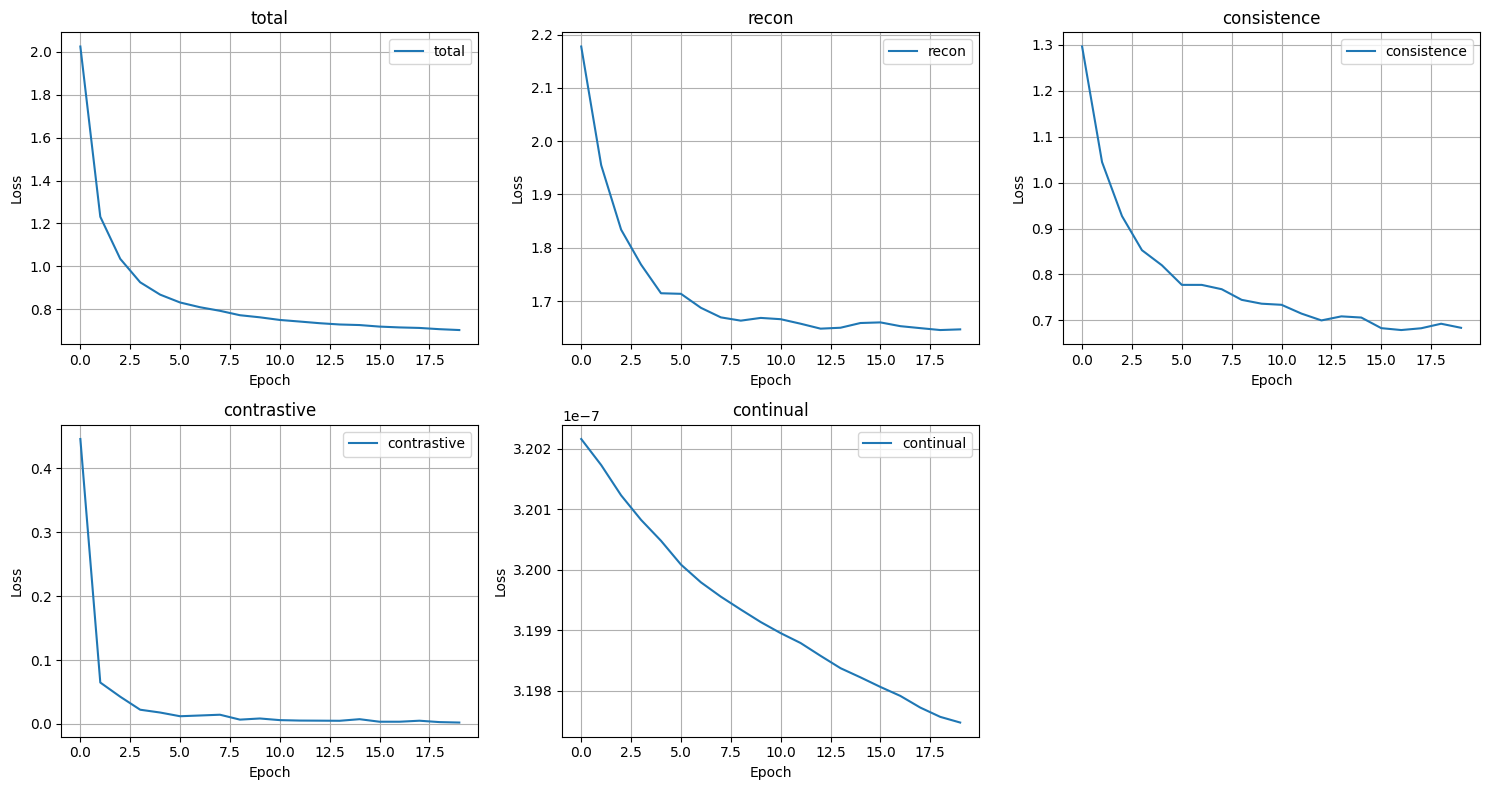

In [ ]:
n_keys = len(loss_log)
n_cols = 3  # or whatever number looks good for your case
n_rows = np.ceil(n_keys / n_cols).astype(int)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)

for idx, (key, value) in enumerate(loss_log.items()):
    row = idx // n_cols
    col = idx % n_cols
    ax = axes[row][col]
    ax.plot(value, label=key)
    ax.set_title(key)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

# Hide any unused subplots if n_keys < n_rows * n_cols
for idx in range(n_keys, n_rows * n_cols):
    row = idx // n_cols
    col = idx % n_cols
    axes[row][col].axis('off')

plt.tight_layout()
plt.show()


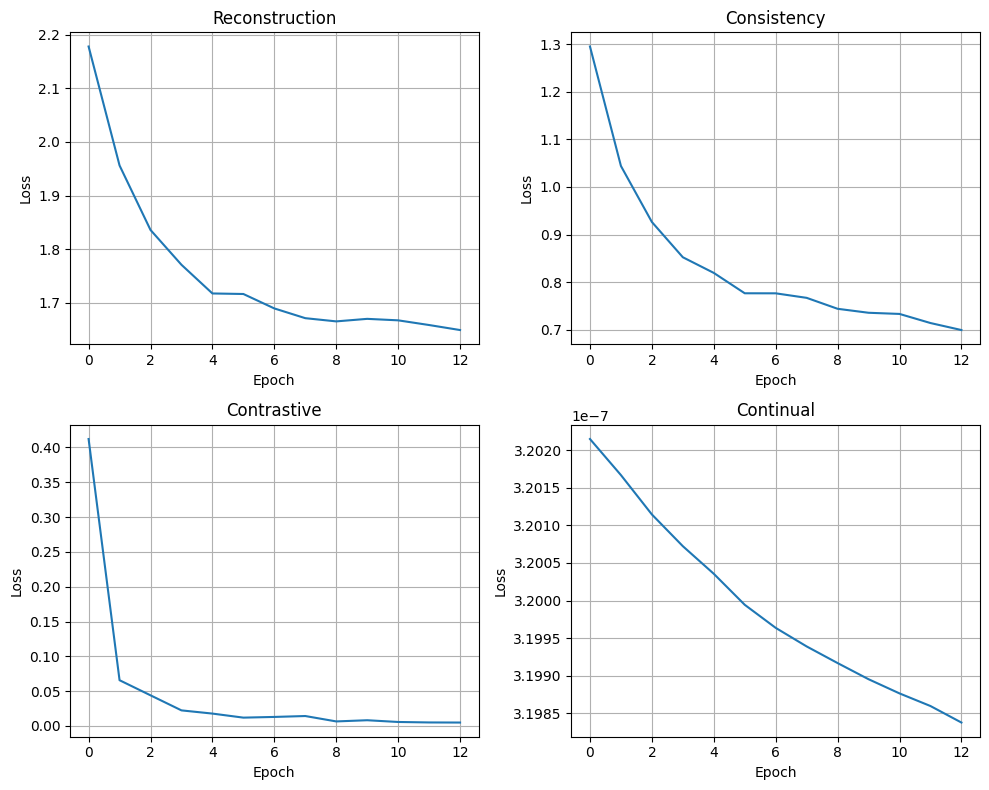

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), squeeze=False)

keys = ['recon', 'consistence', 'contrastive', 'continual']
titles = ['Reconstruction', 'Consistency', 'Contrastive', 'Continual']

axes = axes.flatten()

for ax, key, title in zip(axes, keys, titles):
    ax.plot(loss_log[key], label=title)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)

plt.tight_layout()
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/clr_latent.png", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipython-input-23-591339195.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


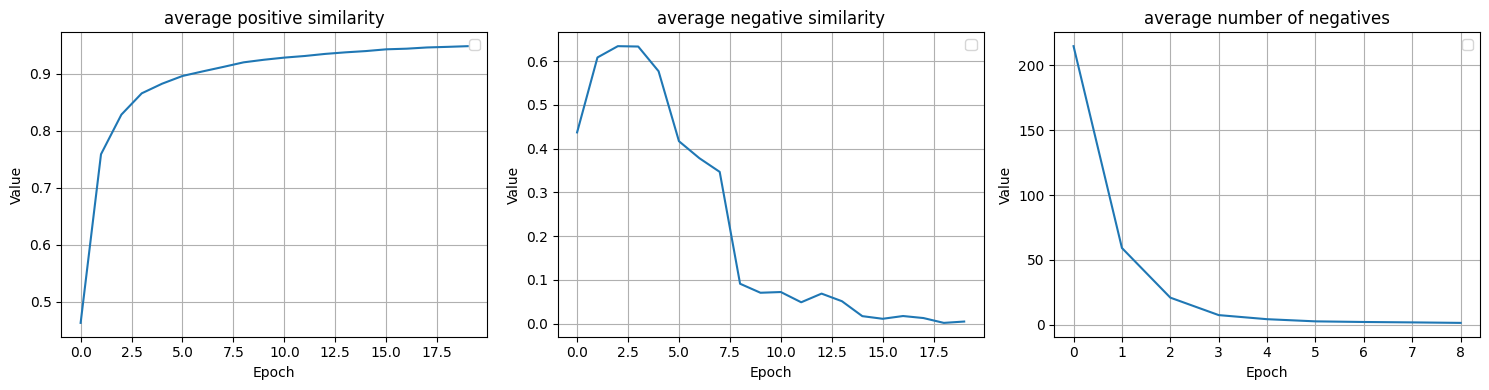

In [ ]:
n_keys = len(contrastive_log)
fig, axes = plt.subplots(1, n_keys, figsize=(5 * n_keys, 4), squeeze=False)

for i, (key, value) in enumerate(contrastive_log.items()):
    ax = axes[0][i]
    ax.plot(value)
    ax.set_title(key)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/clr_latent_siamese.png", dpi=300, bbox_inches='tight')
plt.show()

# Model no-encoder no-continual
A final model is trained by initializing the alignment matrix on the one obtained in phase 2 without encoders.

Given the mismatch between the feature spaces, here we do not continue learning such matrix.

In [ ]:
# Continual learing
continue_alignment = False

# Load initial state
ewc_info = torch.load('/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/ewc_alignment_noAE.pt', map_location=device)
opt_params = ewc_info['optimal_params']

# Store importance matrix if required
if continue_alignment:
    importance = ewc_info['importance']
else:
    importance = None

In [ ]:
# Set seeds
torch.manual_seed(42)
np.random.seed(42)

# Model instance
model_noCL = scCLR(
    d_input=adata_sc.shape[1],
    d_hidden=64,
    d_latent=32,
    n_cells=n_cells,
    n_spots=n_spots,
    dropout=0.1,
    lambda_recon=1e-3,
    lambda_contrast=1.0,
    lambda_ewc=1.0,
    lambda_consistence=1.0,
    batchsize_scrna=rna_batchsize,
    batchsize_spatial=spatial_batchsize,
    continual_alignment=continue_alignment,
    initial_matrix=opt_params,
    importance_matrix=importance,
    sim_threshold=0.9,
    )

if not continue_alignment:
    # Check alignment matrix has no gradients
    assert all(not p.requires_grad for p in model_noCL.AlignMat.parameters())

    # Set encoders to evalutation (no backprop or gradients)
    model_noCL.AlignMat.eval()

# Pretrained encoders (no Continual Learning)
model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

# Load weights into submodules directly
model_noCL.ST_encoder.load_state_dict(torch.load(model_path + 'spatial_encoder_weights.pth'))
model_noCL.SC_encoder.load_state_dict(torch.load(model_path + 'scrna_encoder_weights.pth'))

# Set optimizer
optimizer = torch.optim.Adam(model_noCL.parameters(), lr=1e-3)

# Move to device
model_noCL.to(device)

Allocating alignment matrix...
Done


scCLR(
  (ST_encoder): EncoderST(
    (pre_fc): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
    )
    (post_fc): Linear(in_features=32, out_features=32, bias=True)
    (gat_layer): GATLayer(
      (conv_layers): ModuleList(
        (0): GATConv(32, 32, heads=1)
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (ST_decoder): DecoderST(
    (model): Sequential(
      (0): Linear(in_features=32, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=155, bias=True)
    )
  )
  (SC_encoder): EncoderSC(
    (model): Sequential(
      (0): Linear(in_features=155, out_features=64, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): ReLU()
      (5): Linear(in_features=64, out_features=32, bias=True)


 10%|█         | 1/10 [01:00<09:00, 60.09s/it]

Epoch 1:
total: 1.9962705373764038
recon: 2.1780529022216797
consistence: 1.2933188676834106
contrastive: 0.43559587001800537
continual: 0.0
average positive similarity: 0.5471284309258828
average negative similarity: 0.5424985881799307
average number of negatives: 254.94871794871796


 20%|██        | 2/10 [01:55<07:40, 57.56s/it]

Epoch 2:
total: 1.187272071838379
recon: 1.9661452770233154
consistence: 1.051995038986206
contrastive: 0.03833693265914917
continual: 0.0
average positive similarity: 0.8372184420243288
average negative similarity: 0.8092675621692951
average number of negatives: 233.53846153846155
Epoch 3:
total: 0.9868515133857727
recon: 1.857988953590393
consistence: 0.9144655466079712
contrastive: 0.012138493359088898
continual: 0.0
average positive similarity: 0.8842526643704145
average negative similarity: 0.7275498631672982
average number of negatives: 163.89743589743588
Plotting UMAP


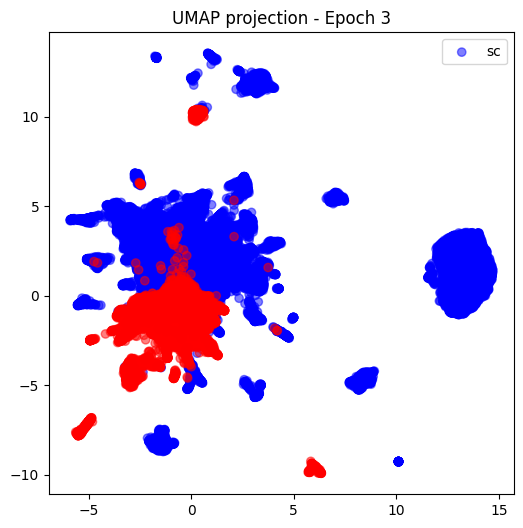

 40%|████      | 4/10 [04:03<06:03, 60.67s/it]

Epoch 4:
total: 0.894991934299469
recon: 1.7955905199050903
consistence: 0.840209424495697
contrastive: 0.011194231919944286
continual: 0.0
average positive similarity: 0.9024547231503022
average negative similarity: 0.5464825072349646
average number of negatives: 103.38461538461539


 50%|█████     | 5/10 [04:59<04:55, 59.09s/it]

Epoch 5:
total: 0.8411007523536682
recon: 1.7705957889556885
consistence: 0.8173922300338745
contrastive: 0.009517393074929714
continual: 0.0
average positive similarity: 0.9147513524079934
average negative similarity: 0.37455429022128767
average number of negatives: 63.794871794871796
Epoch 6:
total: 0.8065547347068787
recon: 1.758833646774292
consistence: 0.7953851222991943
contrastive: 0.008212405256927013
continual: 0.0
average positive similarity: 0.9246383171815139
average negative similarity: 0.2543782557432468
average number of negatives: 37.97435897435897
Plotting UMAP


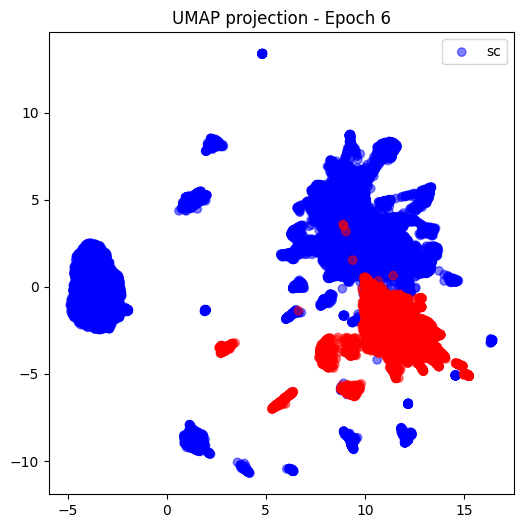

 70%|███████   | 7/10 [07:07<03:03, 61.04s/it]

Epoch 7:
total: 0.780413806438446
recon: 1.7638592720031738
consistence: 0.7763537168502808
contrastive: 0.005603033117949963
continual: 0.0
average positive similarity: 0.9308192103337019
average negative similarity: 0.17128310333459806
average number of negatives: 23.435897435897434


 80%|████████  | 8/10 [08:09<02:02, 61.41s/it]

Epoch 8:
total: 0.7621964812278748
recon: 1.7717113494873047
consistence: 0.7327983975410461
contrastive: 0.004605722613632679
continual: 0.0
average positive similarity: 0.9371919433275858
average negative similarity: 0.1155472980477871
average number of negatives: 13.333333333333334
Epoch 9:
total: 0.7458924651145935
recon: 1.77284574508667
consistence: 0.7556261420249939
contrastive: 0.0036625200882554054
continual: 0.0
average positive similarity: 0.9409492550752102
average negative similarity: 0.08976177966747528
average number of negatives: 9.615384615384615
Plotting UMAP


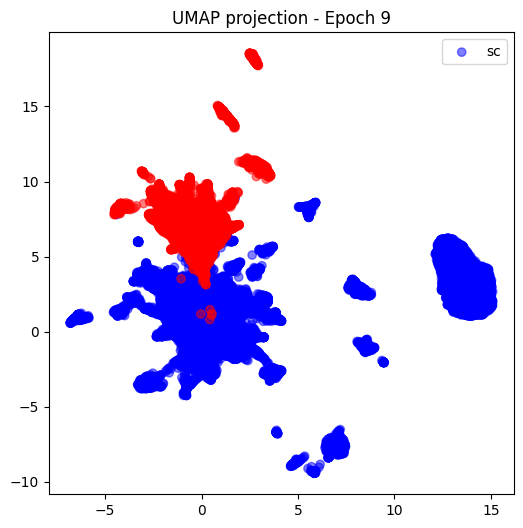

100%|██████████| 10/10 [10:18<00:00, 61.83s/it]

Epoch 10:
total: 0.7346073389053345
recon: 1.7856426239013672
consistence: 0.7096104621887207
contrastive: 0.003861661534756422
continual: 0.0
average positive similarity: 0.9438404181064703
average negative similarity: 0.06720485251683456
average number of negatives: 7.512820512820513


In [ ]:
# Training parameters
num_epoch = 10
log_every_n_epochs = 1
umap_every_n_epochs = 3

# Logs
loss_log_noCL = {"total": [], "recon": [], "consistence": [], "contrastive": [], "continual": []}
contrastive_log_noCL = {"average positive similarity": [], "average negative similarity": [], "average number of negatives": []}

# Early stopper
early_stop = NegativeCountPatience(patience=100)

# Loop
for epoch in tqdm(range(num_epoch)):
        model_noCL.train()

        total_loss = total_recon = total_const = total_align = total_contr = 0.0

        # lists to monitor similarity across positive/negative keys
        pos_sim_vec = []
        neg_sim_vec = []
        negatives_vec = []
        for spatial_batch, rna_batch in zip(spatial_loader, rna_loader):
            ST_fit_batch, ST_edge_batch, ST_index = spatial_batch
            SC_fit_batch, SC_index = rna_batch

            # Zero gradient
            optimizer.zero_grad()

            loss, loss_sc, loss_st, consistence_loss, alignment, contrastive, pos_avg, neg_avg, number_neg = model_noCL(
                ST_fit_batch,
                ST_edge_batch,
                SC_fit_batch,
                SC_index,
                ST_index,
                full_st,
                full_edge_index,
                full_sc)

            # Increment epoch losses
            total_loss += loss
            total_recon += (loss_sc + loss_st)
            total_const += consistence_loss
            total_align += alignment
            total_contr += contrastive

            # Append similarities
            pos_sim_vec.append(pos_avg)
            neg_sim_vec.append(neg_avg)
            negatives_vec.append(number_neg)

            # Backward pass and gradient step
            loss.backward()
            optimizer.step()

        # Average out cumulative epoch losses over number of steps
        avg_loss = total_loss / steps
        avg_recon = total_recon / steps
        avg_const = total_const / steps
        avg_align = total_align / steps
        avg_contr = total_contr / steps

        # Compute average similarity per epoch
        pos_sim_epoch = np.mean(pos_sim_vec)
        neg_sim_epoch = np.mean(neg_sim_vec)
        neg_count_epoch = np.mean(negatives_vec)

        # Update logs
        loss_log_noCL["total"].append(avg_loss.detach().cpu())
        loss_log_noCL["recon"].append(avg_recon.detach().cpu())
        loss_log_noCL["consistence"].append(consistence_loss.detach().cpu())
        loss_log_noCL["continual"].append(avg_align.detach().cpu())
        loss_log_noCL["contrastive"].append(avg_contr.detach().cpu())

        contrastive_log_noCL["average positive similarity"].append(pos_sim_epoch)
        contrastive_log_noCL["average negative similarity"].append(neg_sim_epoch)
        contrastive_log_noCL["average number of negatives"].append(neg_count_epoch)

        if (epoch + 1) % log_every_n_epochs == 0:
            print(f"Epoch {epoch+1}:")
            for key, value in loss_log_noCL.items():
                print(f"{key}: {value[-1]}")

            for key, value in contrastive_log_noCL.items():
                print(f"{key}: {value[-1]}")

        # UMAP visualization
        if (epoch + 1) % umap_every_n_epochs == 0:
            with torch.no_grad():
                model_noCL.eval()
                sc_latent, st_latent = model_noCL.encode(full_sc, full_st, full_edge_index)
                print("Plotting UMAP")
                plot_umap(sc_latent, st_latent, epoch+1)

        # Early stopping check
        early_stop(number_neg)
        if early_stop.stop:
            print(f"Stopping early at epoch {epoch} due to no negatives.")
            break



## Results

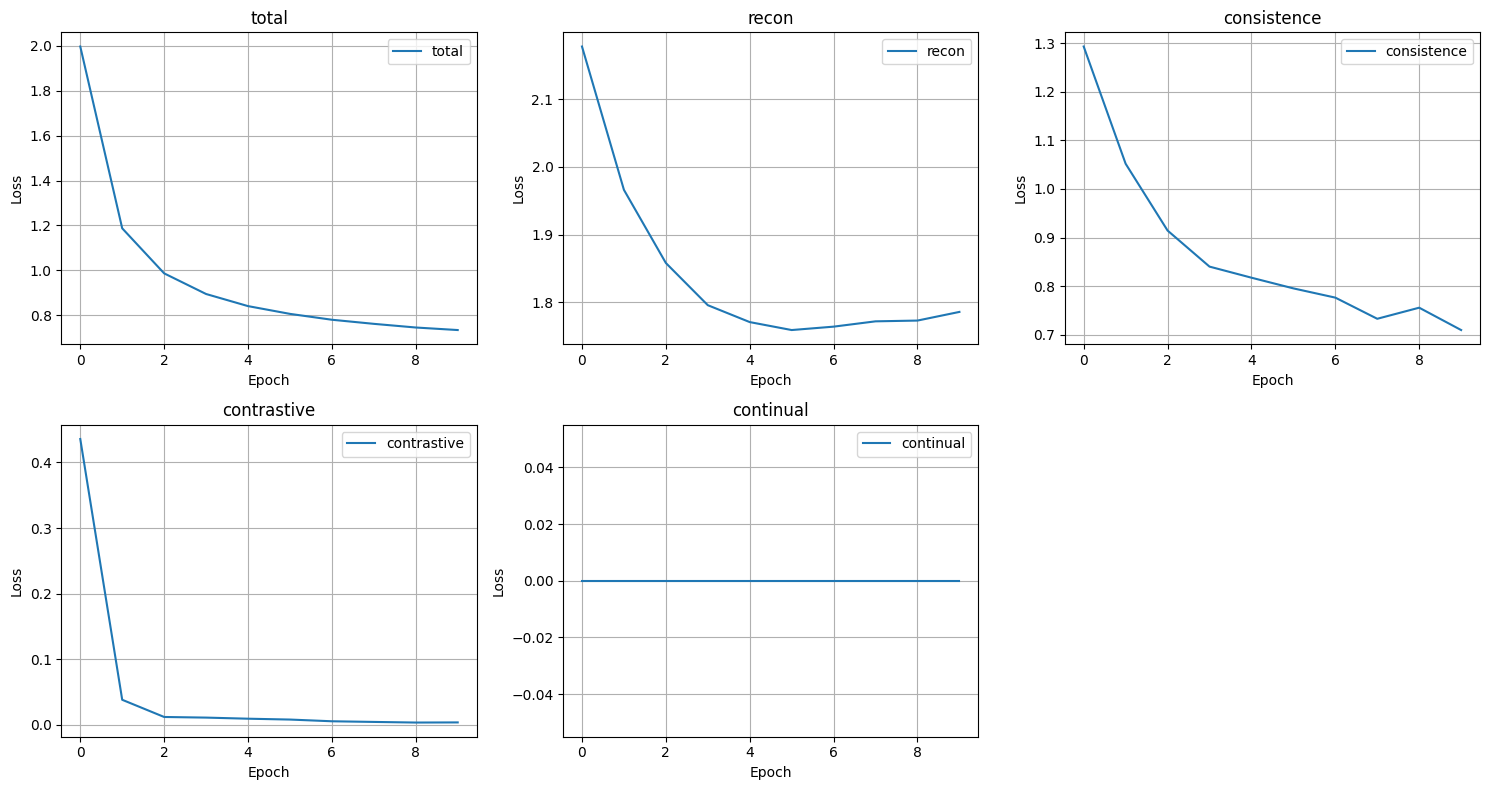

In [ ]:
n_keys = len(loss_log_noCL)
n_cols = 3
n_rows = np.ceil(n_keys / n_cols).astype(int)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)

for idx, (key, value) in enumerate(loss_log_noCL.items()):
    row = idx // n_cols
    col = idx % n_cols
    ax = axes[row][col]
    ax.plot(value, label=key)
    ax.set_title(key)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

for idx in range(n_keys, n_rows * n_cols):
    row = idx // n_cols
    col = idx % n_cols
    axes[row][col].axis('off')

plt.tight_layout()
plt.show()

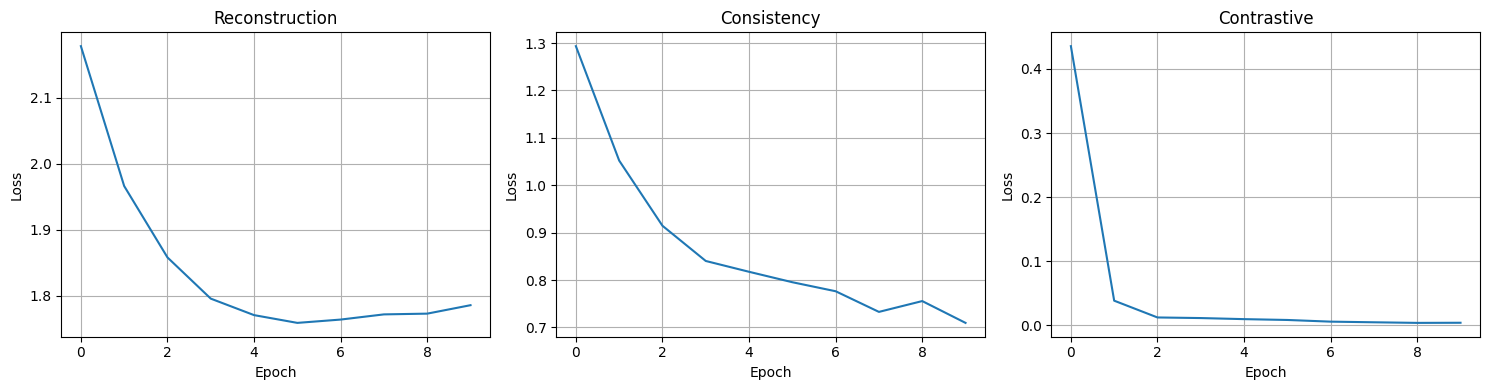

In [ ]:
keys = ['recon', 'consistence', 'contrastive']
titles = ['Reconstruction', 'Consistency', 'Contrastive']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, key, title in zip(axes, keys, titles):
    ax.plot(loss_log_noCL[key], label=title)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)

plt.tight_layout()
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/clr_no_latent.png", dpi=300, bbox_inches='tight')
plt.show()

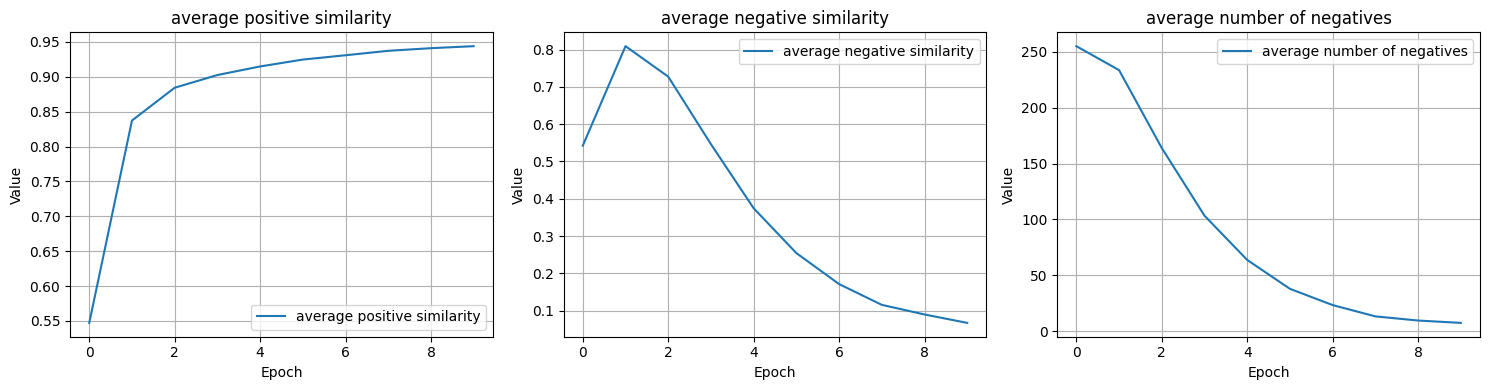

In [ ]:
n_keys = len(contrastive_log_noCL)
fig, axes = plt.subplots(1, n_keys, figsize=(5 * n_keys, 4), squeeze=False)

for i, (key, value) in enumerate(contrastive_log_noCL.items()):
    ax = axes[0][i]
    ax.plot(value, label=key)
    ax.set_title(key)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/clr_no_latent_siamese.png", dpi=300, bbox_inches='tight')
plt.show()

# UMAP
The UMAP embedding on the original common genes space is plotted:

In [ ]:
# Set modality column
adata_sc.obs['Modality'] = 'scrna'
adata_st.obs['Modality'] = 'spatial'

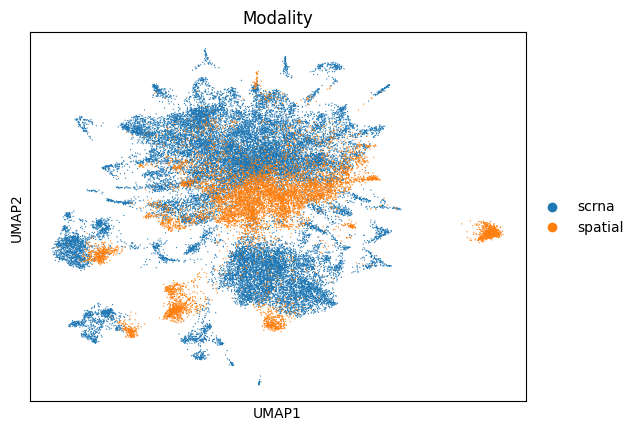

In [ ]:
# Combine anndatas
adata_combined = ad.concat([adata_sc, adata_st])

# Compute neighbors and umao embedding
sc.pp.neighbors(adata_combined, use_rep='X')
sc.tl.umap(adata_combined)

# Plot and save
sc.pl.umap(adata_combined, color='Modality')
# plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/original_umap.png", dpi=300, bbox_inches='tight')
plt.close()

Then, we compute the encoded representation in the latent space and plot the UMAP emebedding:

In [ ]:
latent_sc, latent_st = model.encode(full_sc, full_st, full_edge_index)  # specify model
adata_sc.obsm['X_latent'] = latent_sc.detach().cpu().numpy()
adata_st.obsm['X_latent'] = latent_st.detach().cpu().numpy()

# Combine anndatas
adata_combined = ad.concat([adata_sc, adata_st])

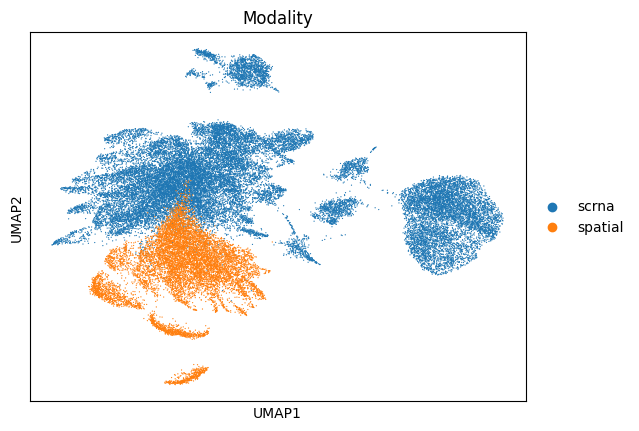

In [ ]:
# Compute neighbors and umao embedding
sc.pp.neighbors(adata_combined, use_rep='X_latent')
sc.tl.umap(adata_combined)

# Plot and save
sc.pl.umap(adata_combined, color='Modality')
# plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/latent_umap.png", dpi=300, bbox_inches='tight')
plt.close()

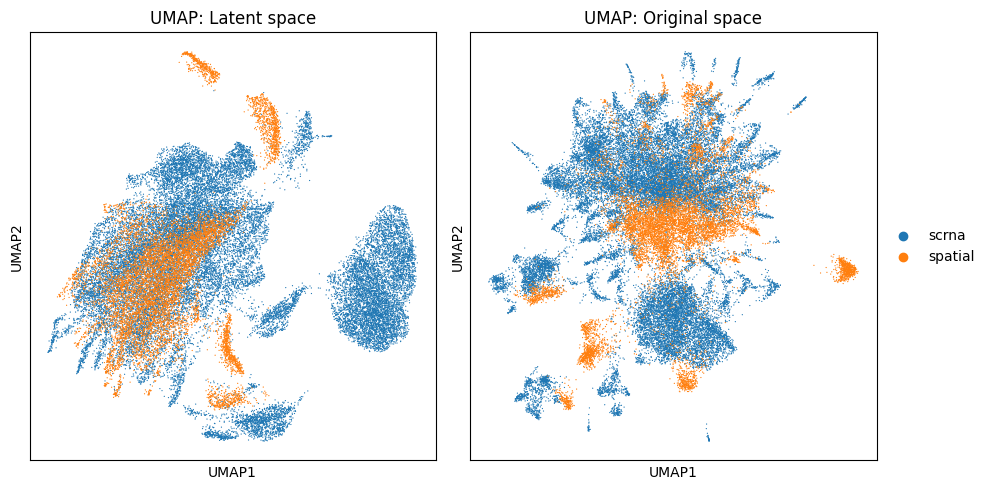

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# First UMAP
sc.pp.neighbors(adata_combined, use_rep='X_latent')
sc.tl.umap(adata_combined)
sc.pl.umap(adata_combined, color='Modality', ax=axes[0], show=False, title='UMAP: Latent space', legend_loc=None)

# Second UMAP
sc.pp.neighbors(adata_combined, use_rep='X')
sc.tl.umap(adata_combined)
sc.pl.umap(adata_combined, color='Modality', ax=axes[1], show=False, title='UMAP: Original space')

plt.tight_layout()
plt.savefig("/content/drive/My Drive/Colab Notebooks/NNDL Project/figures/umap_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

# Save model for downstream task

In [ ]:
model_path = '/content/drive/My Drive/Colab Notebooks/NNDL Project/models_checkpoints/'

# Encoders
torch.save(model.ST_encoder.state_dict(), model_path + 'spatial_encoder_weights_finetuned.pth')
torch.save(model.SC_encoder.state_dict(), model_path + 'scrna_encoder_weights_finetuned.pth')

# Decoders
torch.save(model.ST_decoder.state_dict(), model_path + 'spatial_decoder_weights_finetuned.pth')
torch.save(model.SC_decoder.state_dict(), model_path + 'scrna_decoder_weights_finetuned.pth')

# Alignment matrix
torch.save(model.AlignMat.state_dict(), model_path + 'alignment_matrix_finetuned.pth')